# Exploring the distributed information via SPARQL and helper methods
Next, we answer a few typical quations a user would ask when working with the datasets. A user has to know the addresses of the SPARQL endpoints of interest.  
We basically have 2 options:
1. Define the SPARQL-query, then loop over all SPARQL-Endpoints and digest the response
2. Collect the graphs from the Endpoints, put the together into one graph-object and then operate on this object.
   1. collect via SPARQL, store, put together
   2. directly get the turtlefile via the ontodocker API, store locally, then load from the files and put together into one object. 

Set up things to use the mesh and load participant information:

In [1]:
%load_ext autoreload
# reload modules automatically before each cell
%autoreload 2

import requests
import os
os.environ["REQUESTS_CA_BUNDLE"] = "/etc/ssl/certs/ca-certificates.crt" # if not set by the OS; doesn't hurt

# fixes a bug in SPARQLwrapper
import ssl
ssl._create_default_https_context = ssl._create_unverified_context

In [2]:
from pmd_demo_tools import mesh_tools, sparql_tools

In [3]:
partners_full = mesh_tools.mesh_namespace_grouped_by_company()
_ = mesh_tools.attach_services_in_place(partners_full)

import json
with open('../secrets/tokens.json') as f:
    tokens = json.load(f, object_hook=mesh_tools.namespace_object_hook())

partners_full.Leibniz_Institut_fuer_Werkstofforientierte_Technologien_IWT.iwt.services.ontodocker.token = tokens.Leibniz_Institut_fuer_Werkstofforientierte_Technologien_IWT.ontodocker.token
partners_full.Fraunhofer_IWM.iwm.services.ontodocker.token = tokens.Fraunhofer_IWM.ontodocker.token
partners_full.KIT.kit_3.services.ontodocker_proxy.token = tokens.KIT.ontodocker.token
partners_full.MPISusMat.mpi_susmat.services.ontodocker.token = tokens.MPISusMat.ontodocker.token

selection = ["Leibniz_Institut_fuer_Werkstofforientierte_Technologien_IWT", "Fraunhofer_IWM", "KIT", "MPISusMat"]
partners = mesh_tools.select_toplevel(partners_full, selection, deepcopy=True)

/home/jovyan/work/pmd_mesh-demonstrator/pmd_demo_tools/pmd_demo_tools/mesh_tools.py:582: UserWarning: Failed fetching services for glassomer.pmd.internal: 500 Server Error: Internal Server Error for url: http://mesh-listing.c.pmd.internal/api/v1/pmds/glassomer.pmd.internal.
  warnings.warn(f"Failed fetching services for {zone}: {e}.", category=UserWarning)


## SPARQL queries
To make the following notebook easierly readable, we define some queries in `queries.py`. At the moment, they are hard-coded and will only work for these specific versions of pmdCO and the TTO.

In [4]:
from pmd_demo_tools.query_collection import S355queries
S355queries = S355queries()

You can find queries which prompt for various information:
- `queries.query_materialDesignation()` For which material is data available?  
This reads out the `pmdco:value` stored under `pmdco:materialDesignation`
- `queries.query_processType()`: What process type was performed on S355?
- `queries.query_orientation()`: In what orientation relative to the rolling direction was each specimen cut?
- `queries.query_deviceAndStandard()`: Which device and standard was used for the measurements?
- `queries.query_specimen()`: What is the specimen ID
- `queries.query_csvurl()`: Under which URL can we find the csv-file?

The queries are defined as class methods. They return a dataclass instance, allowing to easily add new methods(queries) and enabling a dot notation and tab completion. They return the query (as a string) and column headers (as a list of strings), corresponding to the returned values of the resp. query.  
Because a `dataclass` is uesd, it is very easy to make returned contents attributes directly accessible via dot-notation while reducing boilerplate code (defining `__init__` etc.):

In [5]:
query = S355queries.material_designation()

print("query ="+query.query)
print("")
print("columns = "+str(query.headers))

query =
        PREFIX pmd: <https://w3id.org/pmd/co/>
        SELECT DISTINCT ?p ?matDesVal
        WHERE {
            ?s a pmd:TestPiece .
            ?p pmd:input ?s .
            ?p pmd:characteristic ?matDes .
            ?matDes a pmd:materialDesignation .
            ?matDes pmd:value ?matDesVal .
        }
        ORDER BY ?p
        

columns = ['uri', 'materialDesignation']


## Explore the datasets
Here, we demonstrate how a simple data exploration can be done by sending queries directly to the intances' SPARQL endpoints and looping over instances. We perform queries using the `SPARQLWrapper` module, wrpeed in some convenience methods.

### Get a first idea
First, we have a look at the accessible endpoints on the instances referenced in `partners_full`, to know which endpoints are accessible.

In [6]:
endpoints = sparql_tools.list_sparql_endpoints(partners_full)

Leibniz_Institut_fuer_Werkstofforientierte_Technologien_IWT
Available SPARQL-endpoints at "ontodocker.iwt.pmd.internal":
https://ontodocker.iwt.pmd.internal/api/v1/jena/pmdco2_tto_example_parallel/sparql

KIT
Available SPARQL-endpoints at "ontodocker-proxy.kit-3.pmd.internal":
http://ontodocker-proxy.kit-3.pmd.internal/api/v1/jena/pmdco2_tto_example_perpendicular/sparql
http://ontodocker-proxy.kit-3.pmd.internal/api/v1/jena/tt_test/sparql

Fraunhofer_IWM
Available SPARQL-endpoints at "ontodocker.iwm.pmd.internal":
https://ontodocker.iwm.pmd.internal/api/v1/jena/test/sparql
https://ontodocker.iwm.pmd.internal/api/v1/jena/pmdco2_tto_example_diagonal/sparql

MPISusMat
Available SPARQL-endpoints at "ontodocker.mpi-susmat.pmd.internal":
http://ontodocker.mpi-susmat.pmd.internal/api/v1/jena/newset/sparql
http://ontodocker.mpi-susmat.pmd.internal/api/v1/jena/not4all/sparql



/home/jovyan/work/pmd_mesh-demonstrator/pmd_demo_tools/pmd_demo_tools/sparql_tools.py:98: UserWarning: [list_sparql_endpoints] Connection error for https://ontodocker-internal.bam-s1.pmd.internal: HTTPSConnectionPool(host='ontodocker-internal.bam-s1.pmd.internal', port=443): Max retries exceeded with url: /api/v1/endpoints (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x7f00f0ad6cd0>: Failed to establish a new connection: [Errno 113] No route to host'))
  warnings.warn(f"[list_sparql_endpoints] Connection error for {base}: {e!s}", category=UserWarning)


# 0.) What datasets on the mesh have information on a material?

In [7]:
query = S355queries.material_designation()
matDes_results = sparql_tools.federated_query(partners=partners_full, query=query.query, columns=query.headers, print_to_screen=True)

Sending query to "https://ontodocker.iwt.pmd.internal/api/v1/jena/pmdco2_tto_example_parallel/sparql". Result:
                                                 uri materialDesignation
0  https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-...                S355
1  https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-...                S355
2  https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-...                S355
3  https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-...                S355

Sending query to "http://ontodocker-proxy.kit-3.pmd.internal/api/v1/jena/pmdco2_tto_example_perpendicular/sparql". Result:
                                                 uri materialDesignation
0  https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-...                S355
1  https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-...                S355
2  https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-...                S355
3  https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-...                S355

Sending query to "http://ontodocke

/home/jovyan/work/pmd_mesh-demonstrator/pmd_demo_tools/pmd_demo_tools/sparql_tools.py:195: UserWarning: [query_instance] Connection error for http://ontodocker-internal.bam-s1.pmd.internal: HTTPConnectionPool(host='ontodocker-internal.bam-s1.pmd.internal', port=80): Max retries exceeded with url: /api/v1/endpoints (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x7f00f0aed110>: Failed to establish a new connection: [Errno 113] No route to host'))
  warnings.warn(f"[query_instance] Connection error for {base}: {e!s}", category=UserWarning)


In [8]:
matDes_results_rns =mesh_tools.RecursiveNamespace(**matDes_results)

In [9]:
matDes_results_rns.KIT_kit_3.ontodocker_proxy.pmdco2_tto_example_perpendicular.result

,uri,materialDesignation
0,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-...,S355
1,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-...,S355
2,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-...,S355
3,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-...,S355


# Exploring information on S355 steel

## 1.) What kind of experimental information is available for S355 steel?

In [10]:
query = S355queries.process_type(material="S355") 
print(query.query)
print(query.headers)

PREFIX pmd: <https://w3id.org/pmd/co/>
        PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
        SELECT distinct ?p ?type
        WHERE {
            ?p a ?type .
            ?matDes a pmd:materialDesignation .
            ?matDes pmd:value "S355"^^xsd:string .
            ?p pmd:characteristic ?matDes .
        }
        ORDER BY ?p
['uri', 'process type']


Let's send this quers to all available SPARQL endpoints on the mesh using `sparql_tools.federated_query()`.  
*Note: You can suppress the output to screen by setting `print_to_screen=False`.*

In [11]:
S355_processes = sparql_tools.federated_query(partners=partners_full, query=query.query, columns=query.headers, print_to_screen=True)

Sending query to "https://ontodocker.iwt.pmd.internal/api/v1/jena/pmdco2_tto_example_parallel/sparql". Result:
                                                 uri  \
0  https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-...   
1  https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-...   
2  https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-...   
3  https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-...   

                          process type  
0  https://w3id.org/pmd/co/TensileTest  
1  https://w3id.org/pmd/co/TensileTest  
2  https://w3id.org/pmd/co/TensileTest  
3  https://w3id.org/pmd/co/TensileTest  

Sending query to "http://ontodocker-proxy.kit-3.pmd.internal/api/v1/jena/pmdco2_tto_example_perpendicular/sparql". Result:
                                                 uri  \
0  https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-...   
1  https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-...   
2  https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-...   
3  https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-...   

/home/jovyan/work/pmd_mesh-demonstrator/pmd_demo_tools/pmd_demo_tools/sparql_tools.py:195: UserWarning: [query_instance] Connection error for http://ontodocker-internal.bam-s1.pmd.internal: HTTPConnectionPool(host='ontodocker-internal.bam-s1.pmd.internal', port=80): Max retries exceeded with url: /api/v1/endpoints (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x7f00f0b19510>: Failed to establish a new connection: [Errno 113] No route to host'))
  warnings.warn(f"[query_instance] Connection error for {base}: {e!s}", category=UserWarning)


### Filtering
Note the empty output for datasets which do not fit the query or when trying to contact services which are hosted on servers not connected to your intance. This can be avoided by specifying `datasets` more precisely, this that irrelevant endpoints are not queries at all. We can collect endpoints of interest from above results.

In [12]:
datasets = ["pmdco2_tto_example_parallel", "pmdco2_tto_example_perpendicular","pmdco2_tto_example_diagonal"]
S355_processes_filtered = sparql_tools.federated_query(partners=partners_full, query=query.query, columns=query.headers, datasets=datasets, print_to_screen=False)
S355_processes_filtered_rns = mesh_tools.RecursiveNamespace(**S355_processes_filtered)

Those results are `pandas.core.frame.DataFrame`s.  
Adjust pandas to improve readability:

In [13]:
import pandas as pd, hashlib
pd.set_option('display.max_colwidth', None)
pd.set_option('display.colheader_justify', 'left')
pd.set_option('display.width', 200)

S355_processes_filtered_rns.Fraunhofer_IWM_iwm.ontodocker.pmdco2_tto_example_diagonal.result

,uri,process type
0,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_process,https://w3id.org/pmd/co/TensileTest
1,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-9_process,https://w3id.org/pmd/co/TensileTest


## 2.) In what orientation relative to the rolling direction was each specimen cut?

In [14]:
query = S355queries.orientation()
orientation_results = sparql_tools.federated_query(partners=partners_full, datasets=datasets, query=query.query, columns=query.headers, print_to_screen=True)
orientation_results_rns = mesh_tools.RecursiveNamespace(**orientation_results)

Sending query to "https://ontodocker.iwt.pmd.internal/api/v1/jena/pmdco2_tto_example_parallel/sparql". Result:
  uri                                                      cut orientation      
0  https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-1_process  in rolling direction
1  https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-2_process  in rolling direction
2  https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-3_process  in rolling direction
3  https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-4_process  in rolling direction

Sending query to "http://ontodocker-proxy.kit-3.pmd.internal/api/v1/jena/pmdco2_tto_example_perpendicular/sparql". Result:
  uri                                                      cut orientation                    
0  https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-5_process  perpendicular to rolling direction
1  https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-6_process  perpendicular to rolling direction
2  https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-7_process  perpendicular t

In [15]:
orientation_results_rns.KIT_kit_3.ontodocker_proxy.pmdco2_tto_example_perpendicular.result

,uri,cut orientation
0,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-5_process,perpendicular to rolling direction
1,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-6_process,perpendicular to rolling direction
2,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-7_process,perpendicular to rolling direction
3,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-8_process,perpendicular to rolling direction


## 3.) What devices were used for the tests and which standards were applied?

In [16]:
query = S355queries.standard_and_extensiometer()
standard_results = sparql_tools.federated_query(partners=partners_full, datasets=datasets, query=query.query, columns=query.headers, print_to_screen=True)
standard_results_rns = mesh_tools.RecursiveNamespace(**standard_results)

Sending query to "https://ontodocker.iwt.pmd.internal/api/v1/jena/pmdco2_tto_example_parallel/sparql". Result:
  uri                                                      extensiometer model standard         
0  https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-1_process  HBM                 DIN EN ISO 17025
1  https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-2_process  HBM                 DIN EN ISO 17025
2  https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-3_process  HBM                 DIN EN ISO 17025
3  https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-4_process  HBM                 DIN EN ISO 17025

Sending query to "http://ontodocker-proxy.kit-3.pmd.internal/api/v1/jena/pmdco2_tto_example_perpendicular/sparql". Result:
  uri                                                      extensiometer model standard         
0  https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-5_process  HBM                 DIN EN ISO 17025
1  https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-6_process  HBM                 DIN EN

## 4.) Which ID was assigned to the specimen?

In [17]:
query = S355queries.specimen_id()
specimen_id_results = sparql_tools.federated_query(partners=partners_full, datasets=datasets, query=query.query, columns=query.headers, print_to_screen=True)
specimen_id_results_rns = mesh_tools.RecursiveNamespace(**specimen_id_results)

Sending query to "https://ontodocker.iwt.pmd.internal/api/v1/jena/pmdco2_tto_example_parallel/sparql". Result:
  uri                                                      specimen id                                                 
0  https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-1_process  https://w3id.org/pmd/ao/tte/testpiece_name/Zx1testpiece/Zx1
1  https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-2_process  https://w3id.org/pmd/ao/tte/testpiece_name/Zx2testpiece/Zx2
2  https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-3_process  https://w3id.org/pmd/ao/tte/testpiece_name/Zx3testpiece/Zx3
3  https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-4_process  https://w3id.org/pmd/ao/tte/testpiece_name/Zx4testpiece/Zx4

Sending query to "http://ontodocker-proxy.kit-3.pmd.internal/api/v1/jena/pmdco2_tto_example_perpendicular/sparql". Result:
  uri                                                      specimen id                                                 
0  https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S

## 5) Accessing and augmenting "raw data"

### 5a.) Obtaining resource locations
For each tensile test, show the URL to the raw tesile-test data:

In [18]:
query = S355queries.csv_url()
csv_url_results = sparql_tools.federated_query(partners=partners_full, datasets=datasets, query=query.query, columns=query.headers, print_to_screen=False)
csv_url_results_rns = mesh_tools.RecursiveNamespace(**csv_url_results)

In [19]:
csv_url_results_rns.Leibniz_Institut_fuer_Werkstofforientierte_Technologien_IWT_iwt.ontodocker.pmdco2_tto_example_parallel.result

,uri,url
0,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-1_process,https://data.mpi-susmat.pmd.internal/Zx1.csv
1,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-2_process,https://data.mpi-susmat.pmd.internal/Zx2.csv
2,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-3_process,https://data.mpi-susmat.pmd.internal/Zx3.csv
3,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-4_process,https://data.mpi-susmat.pmd.internal/Zx4.csv


In [20]:
csv_url_results_rns.KIT_kit_3.ontodocker_proxy.pmdco2_tto_example_perpendicular.result

,uri,url
0,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-5_process,https://data.kit-3.pmd.internal/S355/01_primary_data/Zy1.csv
1,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-6_process,https://data.kit-3.pmd.internal/S355/01_primary_data/Zy2.csv
2,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-7_process,https://data.kit-3.pmd.internal/S355/01_primary_data/Zy3.csv
3,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-8_process,https://data.kit-3.pmd.internal/S355/01_primary_data/Zy4.csv


In [21]:
csv_url_results_rns.Fraunhofer_IWM_iwm.ontodocker.pmdco2_tto_example_diagonal.result

,uri,url
0,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_process,https://ckan.iwm.pmd.internal/en/dataset/1bae2004-1729-46c1-8aeb-25e2652b8485/resource/4ee98330-c256-4c0c-abed-08ff8df6af0f/download/zd3.csv
1,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-9_process,https://ckan.iwm.pmd.internal/en/dataset/1bae2004-1729-46c1-8aeb-25e2652b8485/resource/c6d930b7-e06b-42f0-8a6e-c2ec5f721b21/download/zd2.csv


### 5b.) Augmentation of raw data
Show the content of the csv columns (i.e. the quantitiy and its unit) and relate it ti URI und file URL (resource location):

In [22]:
query = S355queries.csv_columns()
csv_columns_results = sparql_tools.federated_query(partners=partners_full, datasets=datasets, query=query.query, columns=query.headers, print_to_screen=False)
csv_columns_results_rns = mesh_tools.RecursiveNamespace(**csv_columns_results)

In [23]:
csv_columns_results_rns.Fraunhofer_IWM_iwm.ontodocker.pmdco2_tto_example_diagonal.result

,uri,url,name,column number,quantity,unit
0,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_process,https://ckan.iwm.pmd.internal/en/dataset/1bae2004-1729-46c1-8aeb-25e2652b8485/resource/4ee98330-c256-4c0c-abed-08ff8df6af0f/download/zd3.csv,b0,1,https://w3id.org/pmd/co/Duration,http://qudt.org/vocab/unit/SEC
1,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_process,https://ckan.iwm.pmd.internal/en/dataset/1bae2004-1729-46c1-8aeb-25e2652b8485/resource/4ee98330-c256-4c0c-abed-08ff8df6af0f/download/zd3.csv,b1,2,https://w3id.org/pmd/co/CrossheadSeparation,http://qudt.org/vocab/unit/MilliM
2,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_process,https://ckan.iwm.pmd.internal/en/dataset/1bae2004-1729-46c1-8aeb-25e2652b8485/resource/4ee98330-c256-4c0c-abed-08ff8df6af0f/download/zd3.csv,b2,3,https://w3id.org/pmd/co/Force,http://qudt.org/vocab/unit/KiloN
3,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_process,https://ckan.iwm.pmd.internal/en/dataset/1bae2004-1729-46c1-8aeb-25e2652b8485/resource/4ee98330-c256-4c0c-abed-08ff8df6af0f/download/zd3.csv,b3,4,https://w3id.org/pmd/co/PercentageExtension,http://qudt.org/vocab/unit/PERCENT
4,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-9_process,https://ckan.iwm.pmd.internal/en/dataset/1bae2004-1729-46c1-8aeb-25e2652b8485/resource/c6d930b7-e06b-42f0-8a6e-c2ec5f721b21/download/zd2.csv,b4,1,https://w3id.org/pmd/co/Duration,http://qudt.org/vocab/unit/SEC
5,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-9_process,https://ckan.iwm.pmd.internal/en/dataset/1bae2004-1729-46c1-8aeb-25e2652b8485/resource/c6d930b7-e06b-42f0-8a6e-c2ec5f721b21/download/zd2.csv,b5,2,https://w3id.org/pmd/co/CrossheadSeparation,http://qudt.org/vocab/unit/MilliM
6,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-9_process,https://ckan.iwm.pmd.internal/en/dataset/1bae2004-1729-46c1-8aeb-25e2652b8485/resource/c6d930b7-e06b-42f0-8a6e-c2ec5f721b21/download/zd2.csv,b6,3,https://w3id.org/pmd/co/Force,http://qudt.org/vocab/unit/KiloN
7,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-9_process,https://ckan.iwm.pmd.internal/en/dataset/1bae2004-1729-46c1-8aeb-25e2652b8485/resource/c6d930b7-e06b-42f0-8a6e-c2ec5f721b21/download/zd2.csv,b7,4,https://w3id.org/pmd/co/PercentageExtension,http://qudt.org/vocab/unit/PERCENT


## 5c.) Force-displacement curves
Now, we gathered all information to actually plot and interpret the tensile test data in it's "native" form via force-displacement curves by plotting them:

In [24]:
import matplotlib.pyplot as plt
%matplotlib inline

import warnings

First, we store the query results of the data we're interested in simple `lists`

In [25]:
url_results_list = [csv_url_results_rns.Leibniz_Institut_fuer_Werkstofforientierte_Technologien_IWT_iwt.ontodocker.pmdco2_tto_example_parallel.result,
                    csv_url_results_rns.KIT_kit_3.ontodocker_proxy.pmdco2_tto_example_perpendicular.result,
                    csv_url_results_rns.Fraunhofer_IWM_iwm.ontodocker.pmdco2_tto_example_diagonal.result
                   ]

columns_results_list = [csv_columns_results_rns.Leibniz_Institut_fuer_Werkstofforientierte_Technologien_IWT_iwt.ontodocker.pmdco2_tto_example_parallel.result,
                        csv_columns_results_rns.KIT_kit_3.ontodocker_proxy.pmdco2_tto_example_perpendicular.result,
                        csv_columns_results_rns.Fraunhofer_IWM_iwm.ontodocker.pmdco2_tto_example_diagonal.result
                       ]
rolling_direction_results_list =[orientation_results_rns.Leibniz_Institut_fuer_Werkstofforientierte_Technologien_IWT_iwt.ontodocker.pmdco2_tto_example_parallel.result,
                                 orientation_results_rns.KIT_kit_3.ontodocker_proxy.pmdco2_tto_example_perpendicular.result,
                                 orientation_results_rns.Fraunhofer_IWM_iwm.ontodocker.pmdco2_tto_example_diagonal.result
                                ]

In the following, we try to extract as much information as possible from the semantics we collected beforehand. Still we need, some prior knowledge:
- ontologies used for the description to define prefixes for terms for quantities "force" (pmdco) or "MilliM" (qudt)
- the "terms" we're interested in

In [27]:
unit_prefix = "http://qudt.org/vocab/unit/"
pmd_prefix = "https://w3id.org/pmd/co/"
displacement_term = "CrossheadSeparation"
force_term = "Force"

displacement_unit="http://qudt.org/vocab/unit/MilliM"
force_unit="http://qudt.org/vocab/unit/KiloN"

Information like the names of columns of query-results can be extzracted from the `SPARQLquery` instances we used to perform the queries: 

In [28]:
S355queries.orientation().headers

['uri', 'cut orientation']

In [29]:
S355queries.csv_url().headers

['uri', 'url']

In [30]:
S355queries.csv_columns().headers

['uri', 'url', 'name', 'column number', 'quantity', 'unit']

The following cell demonstrates how semantics enable lagely interoperable data-digestion routines:
- we have stored all results in `pandas` `DataFrames`. By obtaining the dataframes column-header directly from the query it was generated from, we can access the information stored in the column:
    - `column_results[S355queries.csv_columns().headers[0]]` gives a list of uris, over which we can iterate
    - `column_results[S355queries.csv_columns().headers[1]]` gives a list of urls, over which we can iterate
    - `column_results[S355queries.csv_columns().headers[4]]` gives a list of all column quantities
- we can relate the uri with the url and by combining knowledge about the uri with the qunatitiy wse're interested in, we can deduce the relevant column number in the csv
- we check units of force and displacement for consistency. Here, also a conversion step could easily be implemented.

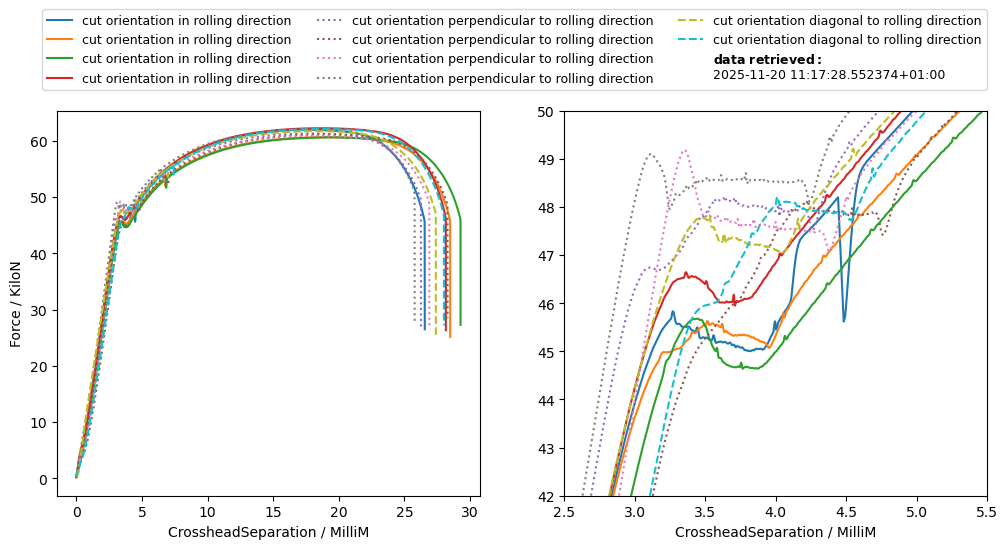

In [31]:
fig_fd, ax_fd = plt.subplots(1,2, figsize=(12,5))
linestyles =("solid", "dotted", "dashed")
for url_results, columns_results, roll_dir_results, linestyle in zip(url_results_list, columns_results_list, rolling_direction_results_list, linestyles):
    for url, uri in zip(url_results[S355queries.csv_url().headers[1]], url_results[S355queries.csv_url().headers[0]]):

        displacement_mask = (columns_results[S355queries.csv_columns().headers[0]] == uri) & (columns_results[S355queries.csv_columns().headers[4]] == pmd_prefix+displacement_term)
        force_mask = (columns_results[S355queries.csv_columns().headers[0]] == uri) & (columns_results[S355queries.csv_columns().headers[4]] == pmd_prefix+force_term)
        roll_dir_mask = roll_dir_results[S355queries.orientation().headers[0]] == uri

        
        if not displacement_unit == columns_results.loc[displacement_mask, S355queries.csv_columns().headers[5]].iloc[0]:
            warnings.warn(f"Inconsitent displacement units detected!", category=UserWarning)
            
        displacement_column_number = int(columns_results.loc[displacement_mask, S355queries.csv_columns().headers[3]].iloc[0])-1
        
        if not force_unit == columns_results.loc[force_mask, S355queries.csv_columns().headers[5]].iloc[0]:
            warnings.warn(f"Inconsitent displacement units detected!", category=UserWarning)
            
        force_column_number = int(columns_results.loc[force_mask, S355queries.csv_columns().headers[3]].iloc[0])-1
        
        roll_dir = roll_dir_results.loc[roll_dir_mask, S355queries.orientation().headers[1]].iloc[0]

        # read csv from ressource location
        csv = pd.read_csv(url, delimiter=";", decimal=",", on_bad_lines='skip', skiprows=[1])
        
        ax_fd[0].plot(csv.iloc[:, displacement_column_number], csv.iloc[:, force_column_number], linestyle=linestyle, label=f"cut orientation {roll_dir}")
        ax_fd[1].plot(csv.iloc[:, displacement_column_number], csv.iloc[:, force_column_number], linestyle=linestyle, label=f"cut orientation {roll_dir}")

ax_fd[0].set_xlabel(displacement_term+" / "+displacement_unit.replace(unit_prefix, ""))
ax_fd[1].set_xlabel(ax_fd[0].get_xlabel())
ax_fd[0].set_ylabel(force_term+" / "+force_unit.replace(unit_prefix, ""))

#dummy plot to adjust legend & to place timestamp
timestamp = pd.Timestamp.now(tz="Europe/Berlin")
ax_fd[0].plot(0,0,ls="None", c="None", label=r"$\bf{{data\ retrieved:}}$"+ f"\n{timestamp}")

ax_fd[1].set_xlim(left=2.5, right=5.5)
ax_fd[1].set_ylim(bottom=42., top=50.)

ax_fd[0].legend(loc="upper left", bbox_to_anchor=(-0.05, 1.28), ncol=3, fontsize=9.)
fig_fd.show()

## 6) More information: `PrimaryData`, `SecondaryData` and `MetaData`

### 6a.) `PrimaryData` - e.g. sample geometries
Data acquired before / after a process either refering to the geometry (e.g. width) of the specimen or as a register of the setup (e.g. original gauge length).

In [33]:
query = S355queries.primary_data()
primary_data_results = sparql_tools.federated_query(partners=partners_full, datasets=datasets, query=query.query, columns=query.headers, print_to_screen=False)
primary_data_results_rns = mesh_tools.RecursiveNamespace(**primary_data_results)

In [34]:
primary_data_results_rns.Fraunhofer_IWM_iwm.ontodocker.pmdco2_tto_example_diagonal.result

,uri,quantity,value,unit
0,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_process,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_crossSectionArea_S0,120.707,http://qudt.org/vocab/unit/MilliM2
1,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_process,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_crossSectionArea_Su,43.924,http://qudt.org/vocab/unit/MilliM2
2,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_process,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_crossSectionArea_s1,120.867,http://qudt.org/vocab/unit/MilliM2
3,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_process,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_crossSectionArea_s2,120.544,http://qudt.org/vocab/unit/MilliM2
4,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_process,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_crossSectionArea_s3,120.71,http://qudt.org/vocab/unit/MilliM2
5,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_process,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_finalGaugeLengthAfterFracture_Lu,79.97,http://qudt.org/vocab/unit/MilliM
6,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_process,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_originalGaugeLength_L0,60.0,http://qudt.org/vocab/unit/MilliM
7,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_process,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_thicknessAfterFracture_au,3.16,http://qudt.org/vocab/unit/MilliM
8,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_process,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_thickness_a1,5.993,http://qudt.org/vocab/unit/MilliM
9,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_process,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_thickness_a2,5.985,http://qudt.org/vocab/unit/MilliM


### 6b.) `SecondaryData` - calculated data
Characteristic values (e.g. test results) determined by equations or algorithms using primary data and metadata for a process (for example directly by the testing machine).

In [35]:
query = S355queries.secondary_data()
secondary_data_results = sparql_tools.federated_query(partners=partners_full, datasets=datasets, query=query.query, columns=query.headers, print_to_screen=False)
secondary_data_results_rns = mesh_tools.RecursiveNamespace(**secondary_data_results)

In [36]:
secondary_data_results_rns.Fraunhofer_IWM_iwm.ontodocker.pmdco2_tto_example_diagonal.result

,uri,quantity,value,unit
0,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_process,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_maximumForce,61.681,http://qudt.org/vocab/unit/kiloN
1,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_process,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_modulusOfElasticity,195.0,http://qudt.org/vocab/unit/GigaPa
2,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_process,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_percentageElongationAfterFracture,33.0,http://qudt.org/vocab/unit/PERCENT
3,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_process,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_percentageReductionOfArea,64.0,http://qudt.org/vocab/unit/PERCENT
4,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_process,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_proofStrength_Rp02,NaN,http://qudt.org/vocab/unit/MegaPa
5,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_process,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_tensileStrength,511.0,http://qudt.org/vocab/unit/MegaPa
6,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_process,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-10_upperYieldStrength,396.0,http://qudt.org/vocab/unit/MegaPa
7,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-9_process,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-9_maximumForce,62.168,http://qudt.org/vocab/unit/kiloN
8,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-9_process,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-9_modulusOfElasticity,201.0,http://qudt.org/vocab/unit/GigaPa
9,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-9_process,https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-9_percentageElongationAfterFracture,33.5,http://qudt.org/vocab/unit/PERCENT


### 6c.) `MetaData` - other "external information
Attributes and additional data concerning the factory, laboratory, the process system and the objects which allow the evaluation of the quality / reliability of the measurements and a systematic search task of a database.

In [37]:
query = S355queries.metadata()
metadata_results = sparql_tools.federated_query(partners=partners_full, datasets=datasets, query=query.query, columns=query.headers, print_to_screen=True)
metadata_results_rns = mesh_tools.RecursiveNamespace(**metadata_results)

Sending query to "https://ontodocker.iwt.pmd.internal/api/v1/jena/pmdco2_tto_example_parallel/sparql". Result:
   uri                                                      Quantity                                                                  value unit                               
0   https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-1_process  https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-1_environmentalTemperature  20.0    http://qudt.org/vocab/unit/DEG_C
1   https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-1_process   https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-1_extensometerGaugeLength  50.0   http://qudt.org/vocab/unit/MilliM
2   https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-1_process           https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-1_transitionPoint   1.6  http://qudt.org/vocab/unit/PERCENT
3   https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-2_process  https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-2_environmentalTemperature  20.0    http://qudt.org/vocab/unit/DEG_C
4   https

# Stress-strain analyis

In [ ]:
testURI = "https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-9_process"
query = S355queries.metadata(testURI)
results = sparql_tools.federated_query(partners=partners_full, datasets=datasets, query=query.query, columns=query.headers, print_to_screen=True)
results_rns = mesh_tools.RecursiveNamespace(**matDes_results)

In [ ]:
metadata_results_rns.Fraunhofer_IWM_iwm.ontodocker.pmdco2_tto_example_diagonal.result # is a pandas dataframe

Using pandas `query` method to extract information:

In [ ]:
results_test_URI = primary_data_results_rns.Fraunhofer_IWM_iwm.ontodocker.pmdco2_tto_example_diagonal.result.query('uri == @testURI')

In [ ]:
results_test_URI

In [ ]:
results_test_URI.query("quantity == 'https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-9_crossSectionArea_S0'")

In [ ]:
s0_value_ds = results_test_URI.query("quantity == 'https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-9_crossSectionArea_S0'")['value']
s0_value_ds

In [ ]:
s0_unit_ds = results_test_URI.query("quantity == 'https://w3id.org/pmd/ao/tte/pmdao-tto-tt-S355-9_crossSectionArea_S0'")['unit']
type(s0_unit_ds)

In [ ]:
print(s0_value_ds.values[0])
type(s0_value_ds.values[0]) # is a string

In [ ]:
import ast
ast.literal_eval(s0_value_ds.values[0]) # convert to the correct type using abstract sysntax tree

In [ ]:
type(ast.literal_eval(s0_value_ds.values[0]))

In [ ]:
type(s0_unit_ds.values[0])